
# HOUSE PRICE PREDICTION – ADVANCED

### Data Science and Machine Learning Capstone Project

**Project Code:** PRCP-1020

**Project Domain:** Real Estate / Data Science

**Project Type:** Regression Analysis and Predictive Modelling

---

## 1. Project Introduction

The real estate industry involves several factors that influence the selling price of residential properties. These factors include the location, size, quality, age, number of bedrooms, bathrooms, garage facilities and other structural characteristics of a house.

The objective of this project is to develop an advanced House Price Prediction system using Data Analysis and Machine Learning techniques.

The project uses the Ames Housing Dataset, which contains information about residential properties in Ames, Iowa, USA. It includes 79 explanatory variables describing different characteristics of houses, along with their actual sale prices.

The project focuses on analysing the dataset, identifying important factors affecting house prices, developing predictive regression models and generating suitable house recommendations based on customer requirements.

## 2. Project Objectives

1. Perform comprehensive Exploratory Data Analysis (EDA) to understand the dataset.
2. Identify and handle missing values, duplicate records and inconsistencies.
3. Analyse the relationship between different house characteristics and their selling prices.
4. Apply feature engineering and data preprocessing techniques.
5. Develop and compare multiple Machine Learning regression algorithms.
6. Evaluate model performance using appropriate statistical metrics.
7. Identify the most influential features affecting house prices.
8. Develop a customer-oriented house recommendation approach based on budget, area and other preferences.

## 3. Problem Statement

To develop a reliable Machine Learning-based system capable of predicting residential house prices using various property characteristics and providing meaningful recommendations to potential home buyers according to their preferences and budget.

## 4. Project Scope

This project covers data collection, data understanding, data cleaning, exploratory analysis, feature engineering, predictive modelling, model evaluation and customer-oriented recommendations.

The final system aims to demonstrate how Data Science and Machine Learning can support informed decision-making in the residential real estate market.

---

**Note:** All original house prices are represented in US Dollars (USD), as the dataset is based on residential property sales in Ames, Iowa.


# 5. Dataset Understanding

This section focuses on understanding the structure, size, variables and characteristics of the Ames Housing Dataset before performing data preprocessing and exploratory data analysis.

The dataset contains information about residential properties, including their physical characteristics, quality, location and actual selling prices.

In [1]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Setting visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:

# Loading the House Price Dataset

df = pd.read_csv("../data.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)


Dataset loaded successfully!
Dataset Shape: (1460, 81)


In [3]:
#displaying the first five records
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
# Checking dataset dimensions

print("Total Number of Records:", df.shape[0])
print("Total Number of Columns:", df.shape[1])

Total Number of Records: 1460
Total Number of Columns: 81


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [6]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000



# 6. Data Quality Assessment

Data Quality Assessment is an important step in the data analysis process. It helps identify errors, missing information, duplicate records and inconsistencies that may affect the accuracy of machine learning models.

In this section, the dataset is examined to identify missing values, duplicate records, data types and inconsistencies. These observations will help determine the appropriate data preprocessing techniques.


In [7]:
# Checking missing values in each column

missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(
    ascending=False
)

print("Columns containing missing values:")
print(missing_values)

Columns containing missing values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtFinType1      37
BsmtCond          37
BsmtQual          37
MasVnrArea         8
Electrical         1
dtype: int64


In [8]:

# Calculating missing value percentages

missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_data = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": missing_percentage
})

missing_data = missing_data[
    missing_data["Missing Values"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_data


,Missing Values,Missing Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


### 6.3 Duplicate Records

Duplicate records are rows that appear more than once in a dataset. Identifying and removing duplicate records helps maintain data quality and prevents repeated observations from affecting model training.

In [9]:
# Checking duplicate records

duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


### 6.4 Numerical and Categorical Features

The dataset contains both numerical and categorical features.

Numerical features represent measurable quantities, while categorical features represent labels or groups. Identifying these features helps us select appropriate preprocessing and machine learning techniques.

In [10]:
# Identifying numerical and categorical columns

numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

categorical_columns = df.select_dtypes(include="object").columns.tolist()

print("Number of Numerical Columns:", len(numerical_columns))
print("Number of Categorical Columns:", len(categorical_columns))

print("\nNumerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Number of Numerical Columns: 38
Number of Categorical Columns: 43

Numerical Columns:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Categorical Columns:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC',

### 6.5 Target Variable Identification

The target variable is the output that a machine learning model aims to predict.

In this project, `SalePrice` is selected as the target variable because our objective is to predict the selling price of houses based on their characteristics.

All other relevant features will be used as input variables for prediction.

In [11]:
# Separating input features and target variable

target = "SalePrice"

X = df.drop(columns=[target, "Id"])
y = df[target]

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nTarget Variable Summary:")
print(y.describe())

Input Features Shape: (1460, 79)
Target Variable Shape: (1460,)

Target Variable Summary:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


# 7. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the patterns, trends, distributions and relationships present in the dataset. It helps identify important factors that influence house prices and supports better decision-making during model development.

### 7.1 Statistical Analysis of House Prices

In this section, we analyze the target variable SalePrice using descriptive statistics to understand the distribution and variation in house prices.

In [12]:
# Statistical analysis of house prices

print("Mean House Price:", y.mean())
print("Median House Price:", y.median())
print("Minimum House Price:", y.min())
print("Maximum House Price:", y.max())
print("Standard Deviation:", y.std())

Mean House Price: 180921.19589041095
Median House Price: 163000.0
Minimum House Price: 34900
Maximum House Price: 755000
Standard Deviation: 79442.50288288663


### 7.2 Distribution of House Prices

A histogram is used to visualize the frequency distribution of house prices. It helps identify the most common price ranges, the spread of prices and possible skewness in the target variable.

In [13]:
# Visualizing the distribution of house prices

plt.figure(figsize=(10, 6))

sns.histplot(y, bins=30, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("House Price (USD)")
plt.ylabel("Frequency")

plt.show()

KeyboardInterrupt: 

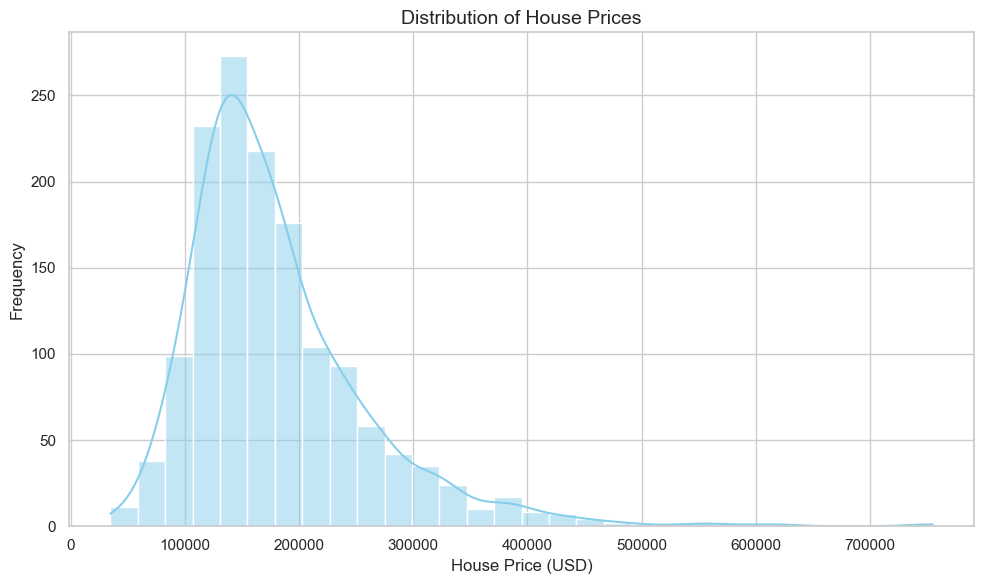

In [14]:
# 7.2 Distribution of House Prices (Histogram)

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="SalePrice",
    bins=30,
    kde=True,
    color="skyblue"
)

plt.title("Distribution of House Prices", fontsize=14)
plt.xlabel("House Price (USD)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### 7.3 Outlier Detection Using Box Plot

A box plot is used to identify potential outliers in house prices. It displays the median, quartiles and spread of the data. Values appearing beyond the whiskers are considered potential outliers and require further investigation.

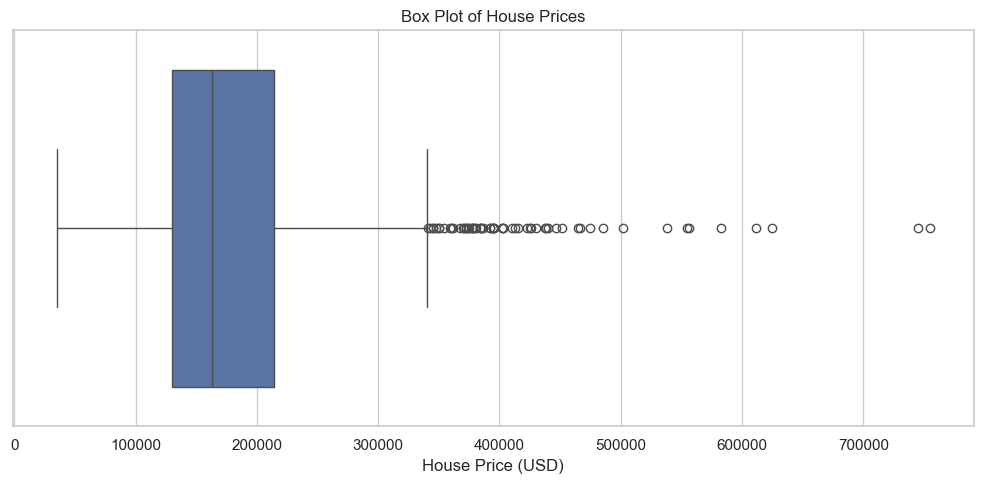

In [15]:
# Visualizing outliers in house prices

plt.figure(figsize=(10, 5))

sns.boxplot(x=df["SalePrice"])

plt.title("Box Plot of House Prices")
plt.xlabel("House Price (USD)")

plt.tight_layout()
plt.show()

### 7.4 Relationship Between Living Area and House Price

In this section, we analyze the relationship between the above-ground living area (GrLivArea) and the selling price (SalePrice) of houses.

A scatter plot is used to identify whether larger houses generally have higher selling prices and to observe any unusual patterns.

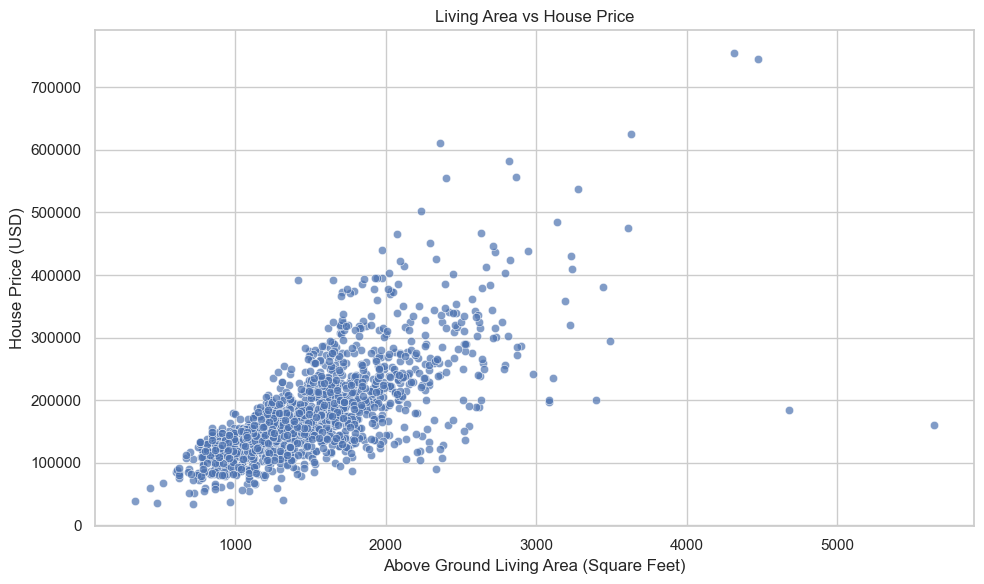

In [16]:
# Relationship between living area and house price

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    alpha=0.7
)

plt.title("Living Area vs House Price")
plt.xlabel("Above Ground Living Area (Square Feet)")
plt.ylabel("House Price (USD)")

plt.tight_layout()
plt.show()

### 7.5 Correlation Analysis

Correlation analysis is used to measure the strength and direction of relationships between numerical variables.

The correlation coefficient ranges from -1 to +1:

- +1 indicates a perfect positive correlation.
- -1 indicates a perfect negative correlation.
- 0 indicates no linear correlation.

This analysis helps identify numerical features that are strongly associated with house prices.

In [17]:
# Analyzing correlation with house prices

numerical_data = df.select_dtypes(include=np.number).drop(
    columns=["Id"], errors="ignore"
)

price_correlation = numerical_data.corr()["SalePrice"].sort_values(
    ascending=False
)

print("Correlation of Numerical Features with SalePrice:")
print(price_correlation)

Correlation of Numerical Features with SalePrice:
SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr  

### 7.6 Correlation Heatmap

A correlation heatmap is a graphical representation of correlation coefficients between numerical variables. Different colours represent the strength and direction of relationships.

It helps identify important numerical features associated with house prices and also highlights relationships among input features.

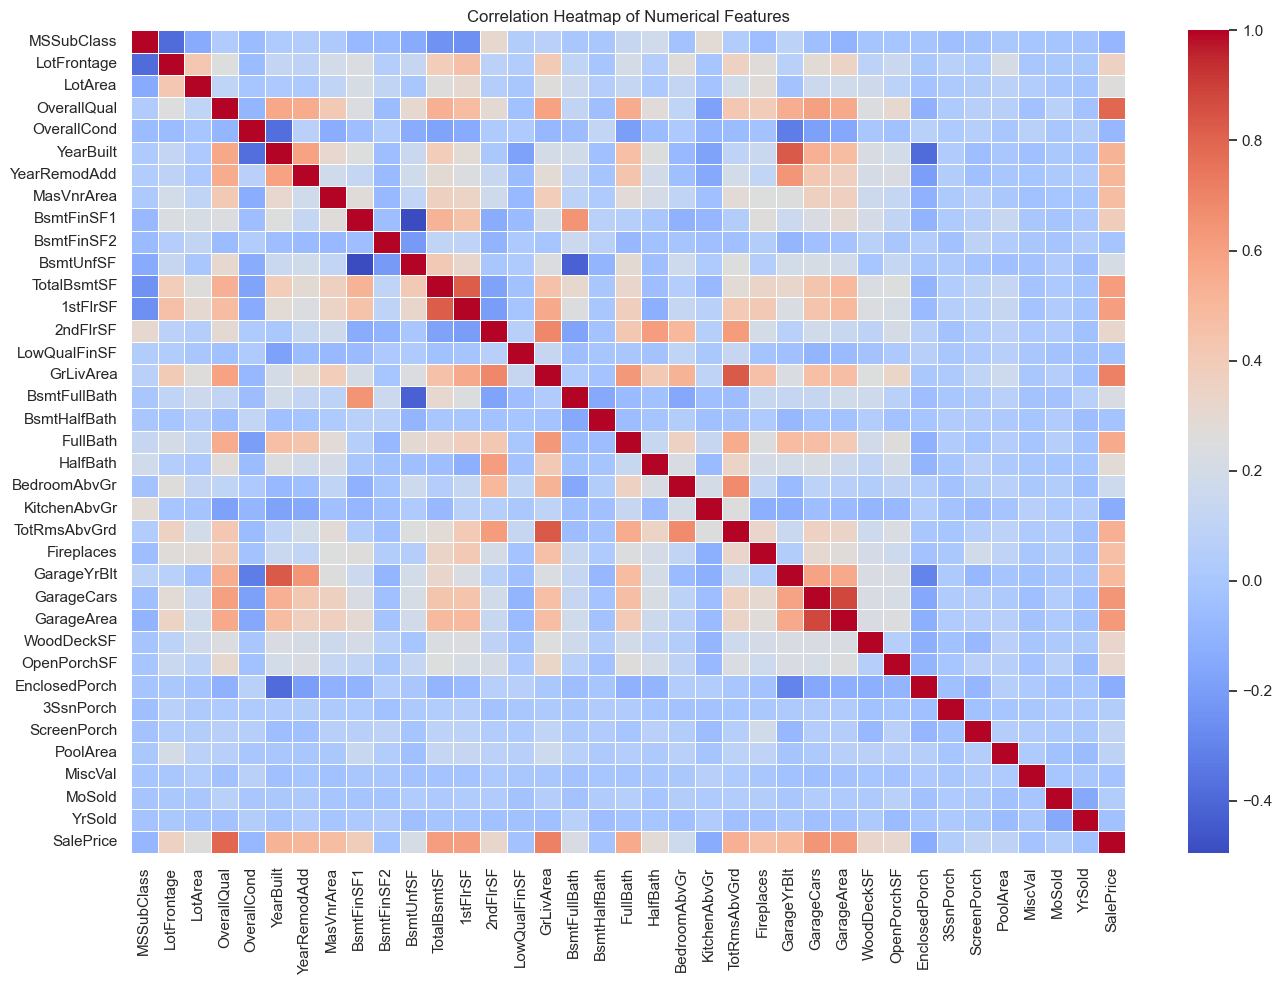

In [18]:
# Visualizing correlation using a heatmap

plt.figure(figsize=(14, 10))

correlation_matrix = numerical_data.corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    annot=False,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")

plt.tight_layout()
plt.show()

### 7.7 Categorical Feature Analysis – Neighborhood

Neighborhood is an important categorical feature in the house price dataset. In this section, we compare average house prices across different neighborhoods to identify variations in selling prices based on location.

In [19]:
# 7.7 Analyzing Average House Prices by Neighborhood

neighborhood_prices = (
    df.groupby("Neighborhood")["SalePrice"]
    .mean()
    .sort_values(ascending=False)
)

print("Average House Price by Neighborhood:")
print(neighborhood_prices.round(2))

Average House Price by Neighborhood:
Neighborhood
NoRidge    335295.32
NridgHt    316270.62
StoneBr    310499.00
Timber     242247.45
Veenker    238772.73
Somerst    225379.84
ClearCr    212565.43
Crawfor    210624.73
CollgCr    197965.77
Blmngtn    194870.88
Gilbert    192854.51
NWAmes     189050.07
SawyerW    186555.80
Mitchel    156270.12
NAmes      145847.08
NPkVill    142694.44
SWISU      142591.36
Blueste    137500.00
Sawyer     136793.14
OldTown    128225.30
Edwards    128219.70
BrkSide    124834.05
BrDale     104493.75
IDOTRR     100123.78
MeadowV     98576.47
Name: SalePrice, dtype: float64


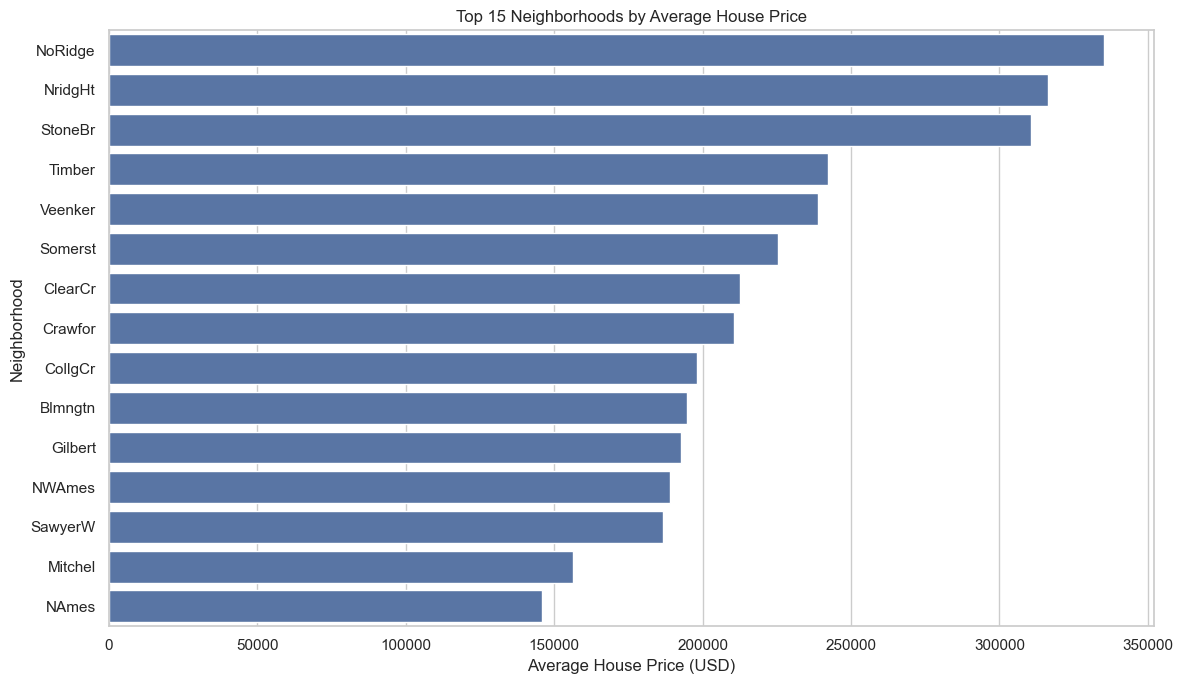

In [20]:
# Visualizing average house prices by neighborhood

plt.figure(figsize=(12, 7))

sns.barplot(
    x=neighborhood_prices.head(15).values,
    y=neighborhood_prices.head(15).index
)

plt.title("Top 15 Neighborhoods by Average House Price")
plt.xlabel("Average House Price (USD)")
plt.ylabel("Neighborhood")

plt.tight_layout()
plt.show()

### 7.8 House Style and Overall Quality Analysis

This section examines the relationship between house style, overall quality and selling prices. It helps identify how structural design and construction quality are associated with house prices.

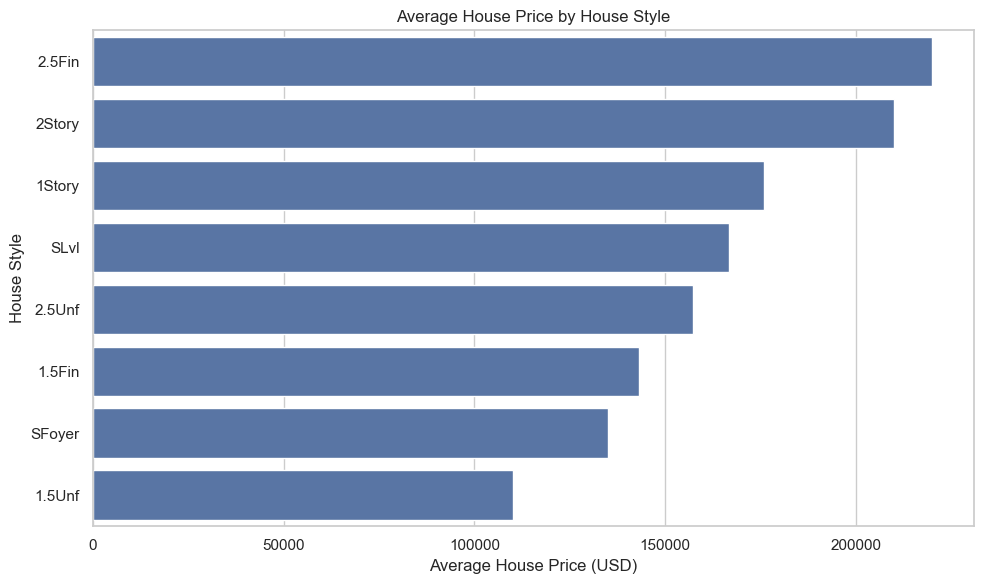

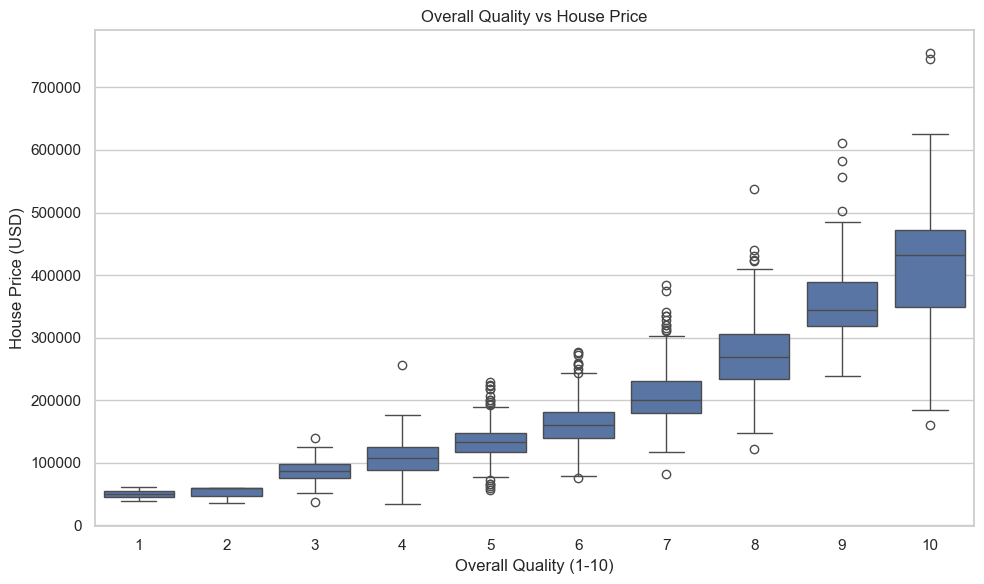

In [21]:
# Analyzing average house prices by house style

style_prices = (
    df.groupby("HouseStyle")["SalePrice"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=style_prices.values,
    y=style_prices.index
)

plt.title("Average House Price by House Style")
plt.xlabel("Average House Price (USD)")
plt.ylabel("House Style")

plt.tight_layout()
plt.show()


# Analyzing overall quality against house prices

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="OverallQual",
    y="SalePrice"
)

plt.title("Overall Quality vs House Price")
plt.xlabel("Overall Quality (1-10)")
plt.ylabel("House Price (USD)")

plt.tight_layout()
plt.show()

### 7.9 Key Findings from Exploratory Data Analysis

The exploratory data analysis provides the following important observations:

1. House prices show variations across different price ranges.
2. Living area has a positive relationship with house prices.
3. Certain numerical features show stronger correlations with the target variable.
4. House prices vary across different neighborhoods.
5. Overall house quality is an important factor to investigate when predicting selling prices.
6. Potential outliers are present and should be examined carefully before model development.

These findings help guide feature selection, preprocessing and machine learning model development.

# 8. Data Preprocessing

Data preprocessing is the process of cleaning and transforming raw data into a suitable format for machine learning algorithms.

The following operations will be performed:

1. Handling missing values.
2. Separating numerical and categorical features.
3. Encoding categorical variables.
4. Splitting the dataset into training and testing sets.
5. Preparing preprocessing pipelines to avoid data leakage.

In [22]:
# Checking missing values before preprocessing

missing_counts = X.isnull().sum()

missing_counts = missing_counts[missing_counts > 0]

print("Total columns containing missing values:", len(missing_counts))
print("\nMissing values in each column:")
print(missing_counts.sort_values(ascending=False))

Total columns containing missing values: 19

Missing values in each column:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtFinType1      37
BsmtCond          37
BsmtQual          37
MasVnrArea         8
Electrical         1
dtype: int64


### 8.1 Handling Missing Values and Encoding Categorical Features

Missing values are handled using median imputation for numerical features and a separate missing category for categorical features.

Categorical features are converted into numerical representations using One-Hot Encoding so that machine learning algorithms can process them.

In [23]:
# 8.1 Data Preprocessing

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Identifying numerical and categorical features
numerical_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include="object").columns.tolist()

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combining both preprocessing methods
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

# Splitting dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Applying preprocessing
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)
print("\nMissing values handled and categorical features encoded successfully!")

Training data shape: (1168, 304)
Testing data shape: (292, 304)
Training target shape: (1168,)
Testing target shape: (292,)

Missing values handled and categorical features encoded successfully!


# 9. Machine Learning Model Development

In this section, different machine learning regression algorithms are trained using the preprocessed housing dataset.

The objective is to identify the model that can predict house selling prices with the lowest prediction error and best generalization performance.

The following algorithms are selected:
1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor

In [24]:
# 9.2 Training Machine Learning Models

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

# Creating machine learning models
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        random_state=42
    )
}

# Training all models
trained_models = {}

for name, model in models.items():
    print("Training:", name)

    model.fit(X_train_processed, y_train)

    trained_models[name] = model

print("\nAll machine learning models trained successfully!")

Training: Linear Regression
Training: Decision Tree
Training: Random Forest
Training: Gradient Boosting

All machine learning models trained successfully!


# 10. Model Evaluation and Comparison

Model evaluation is performed to measure the predictive performance of trained machine learning algorithms.

The models are evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE) and R-squared (R²).

These metrics help compare prediction errors and identify the most suitable model for house price prediction.

In [25]:
# 10.1 Evaluating All Trained Models

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

results = []

for name, model in trained_models.items():

    # Predicting house prices
    predictions = model.predict(X_test_processed)

    # Calculating evaluation metrics
    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Creating comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(3))

MODEL PERFORMANCE COMPARISON


,Model,MAE,MSE,RMSE,R2 Score
3,Gradient Boosting,17950.525,7.980599e+08,28249.954,0.896
2,Random Forest,17717.937,8.655010e+08,29419.399,0.887
0,Linear Regression,20436.886,9.618700e+08,31014.029,0.875
1,Decision Tree,29908.089,2.244883e+09,47380.197,0.707


### 10.2 Visual Comparison of Model Performance

Visual comparison is performed to understand the differences in predictive performance among the trained regression models.

The MAE, RMSE and R-squared scores are visualized to identify the model with lower prediction errors and better explanatory performance.

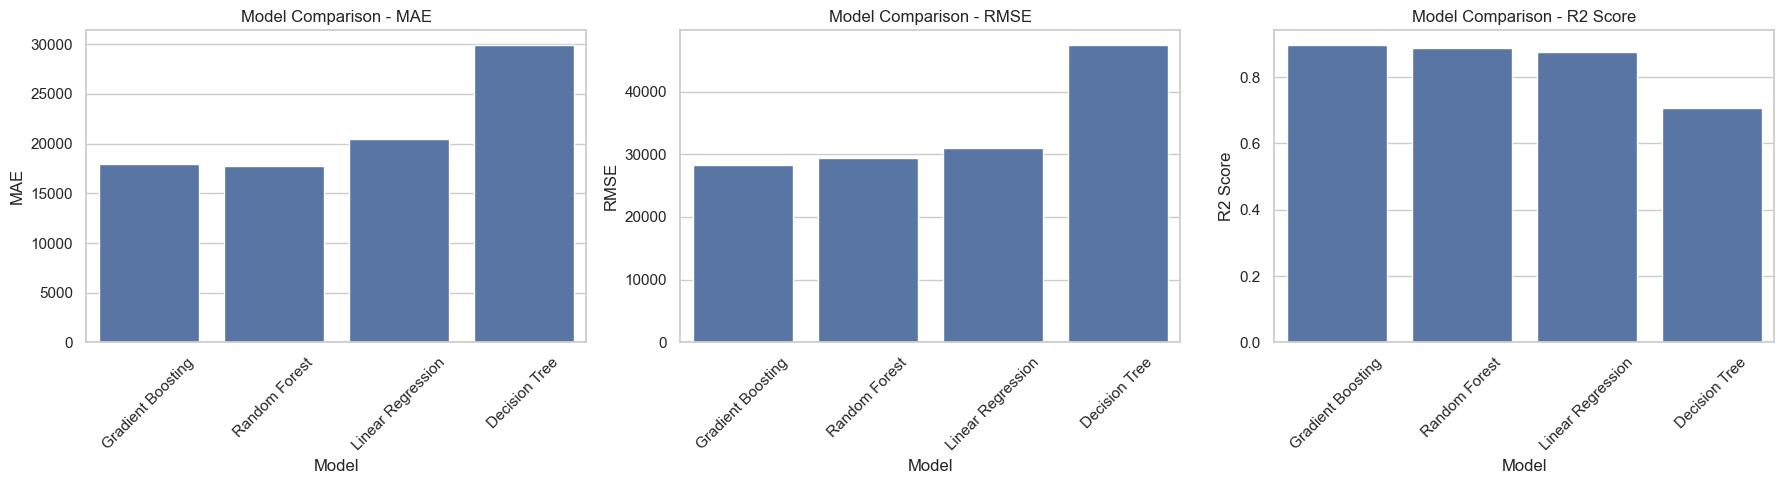

In [26]:
# 10.2 Comparing Model Performance Visually

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# MAE comparison
sns.barplot(data=results_df, x="Model", y="MAE", ax=axes[0])
axes[0].set_title("Model Comparison - MAE")
axes[0].tick_params(axis="x", rotation=45)

# RMSE comparison
sns.barplot(data=results_df, x="Model", y="RMSE", ax=axes[1])
axes[1].set_title("Model Comparison - RMSE")
axes[1].tick_params(axis="x", rotation=45)

# R2 comparison
sns.barplot(data=results_df, x="Model", y="R2 Score", ax=axes[2])
axes[2].set_title("Model Comparison - R2 Score")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### 10.3 Actual vs Predicted House Prices

This visualization compares actual house prices with the prices predicted by the selected machine learning model.

A closer alignment of predicted values with the actual values indicates better predictive performance.

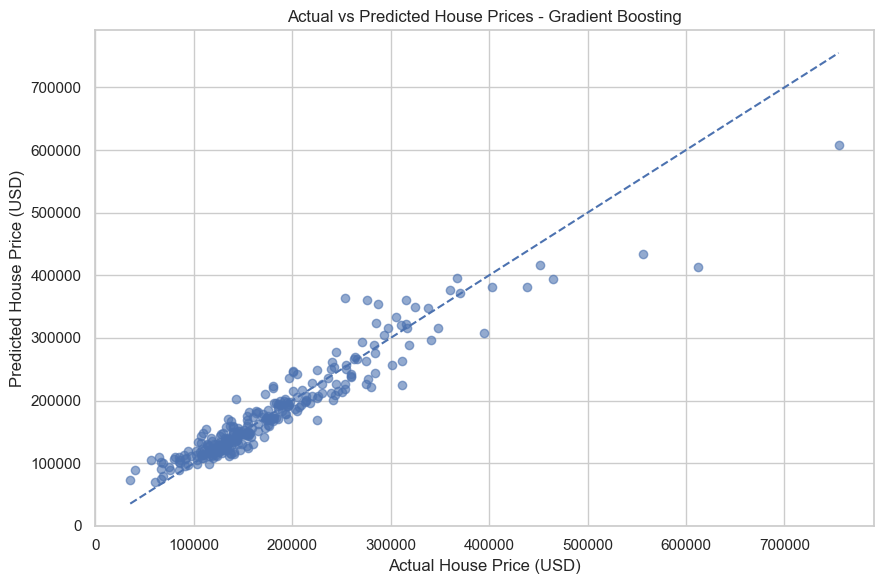

Selected Model: Gradient Boosting


In [27]:
# 10.3 Actual vs Predicted Price Visualization

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test_processed)

plt.figure(figsize=(9, 6))

plt.scatter(y_test, best_predictions, alpha=0.6)

# Reference line for perfect predictions
min_price = min(y_test.min(), best_predictions.min())
max_price = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.title(f"Actual vs Predicted House Prices - {best_model_name}")
plt.xlabel("Actual House Price (USD)")
plt.ylabel("Predicted House Price (USD)")

plt.tight_layout()
plt.show()

print("Selected Model:", best_model_name)

# 11. Cross-Validation

Cross-validation is used to evaluate the consistency and reliability of machine learning models.

In this project, 5-fold cross-validation is applied to compare model performance across different subsets of the training data. RMSE is used as the evaluation metric. A lower average CV RMSE indicates better predictive performance.

In [28]:
from sklearn.model_selection import cross_val_score
from sklearn.base import clone
from sklearn.pipeline import Pipeline

cv_results = []

for name, model in models.items():

    full_pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", clone(model))
    ])

    scores = cross_val_score(
        full_pipeline,
        X_train,
        y_train,
        cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    rmse_scores = -scores

    cv_results.append({
        "Model": name,
        "Mean CV RMSE": rmse_scores.mean(),
        "CV RMSE Std": rmse_scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="Mean CV RMSE",
    ascending=True
)

print("5-FOLD CROSS-VALIDATION RESULTS")
display(cv_results_df.round(2))

5-FOLD CROSS-VALIDATION RESULTS


,Model,Mean CV RMSE,CV RMSE Std
3,Gradient Boosting,30148.66,4853.06
2,Random Forest,30571.90,4820.84
0,Linear Regression,34936.18,8328.87
1,Decision Tree,45137.04,5958.41


# 12. Final Model Selection

After comparing the models using cross-validation, the model with the lowest Mean CV RMSE is selected as the final candidate.

The selected model is retrained on the complete training dataset and evaluated on the unseen testing dataset to check its prediction performance.

In [29]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select the model with the lowest cross-validation RMSE
best_model_name = cv_results_df.iloc[0]["Model"]
best_estimator = clone(models[best_model_name])

# Create a complete pipeline
final_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", best_estimator)
])

# Train the final model
final_pipeline.fit(X_train, y_train)

# Predict house prices on unseen test data
final_predictions = final_pipeline.predict(X_test)

# Evaluate final model
final_mae = mean_absolute_error(y_test, final_predictions)
final_mse = mean_squared_error(y_test, final_predictions)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, final_predictions)

print("FINAL SELECTED MODEL:", best_model_name)
print("Mean Absolute Error:", round(final_mae, 2))
print("Mean Squared Error:", round(final_mse, 2))
print("Root Mean Squared Error:", round(final_rmse, 2))
print("R2 Score:", round(final_r2, 4))

FINAL SELECTED MODEL: Gradient Boosting
Mean Absolute Error: 17950.53
Mean Squared Error: 798059874.35
Root Mean Squared Error: 28249.95
R2 Score: 0.896


# 13. Feature Importance Analysis

Feature importance analysis identifies the property characteristics that contribute most to the predictions made by the selected machine learning model.

This analysis helps us understand which factors have the greatest influence on predicted house prices.

In [30]:
# Get feature names after preprocessing
feature_names = final_pipeline.named_steps["preprocessor"].get_feature_names_out()

# Get the trained model
final_model = final_pipeline.named_steps["model"]

# Calculate feature importance
if hasattr(final_model, "feature_importances_"):
    importance_values = final_model.feature_importances_

elif hasattr(final_model, "coef_"):
    importance_values = np.abs(final_model.coef_)

else:
    raise ValueError("Feature importance is not available for this model.")

# Create a feature importance table
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Display the top 15 important features
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

top_features = feature_importance_df.head(15)

display(top_features.round(4))

,Feature,Importance
3,num__OverallQual,0.5174
15,num__GrLivArea,0.1547
25,num__GarageCars,0.0481
8,num__BsmtFinSF1,0.0355
11,num__TotalBsmtSF,0.0350
12,num__1stFlrSF,0.0300
13,num__2ndFlrSF,0.0267
2,num__LotArea,0.0169
5,num__YearBuilt,0.0162
185,cat__BsmtQual_Ex,0.0146


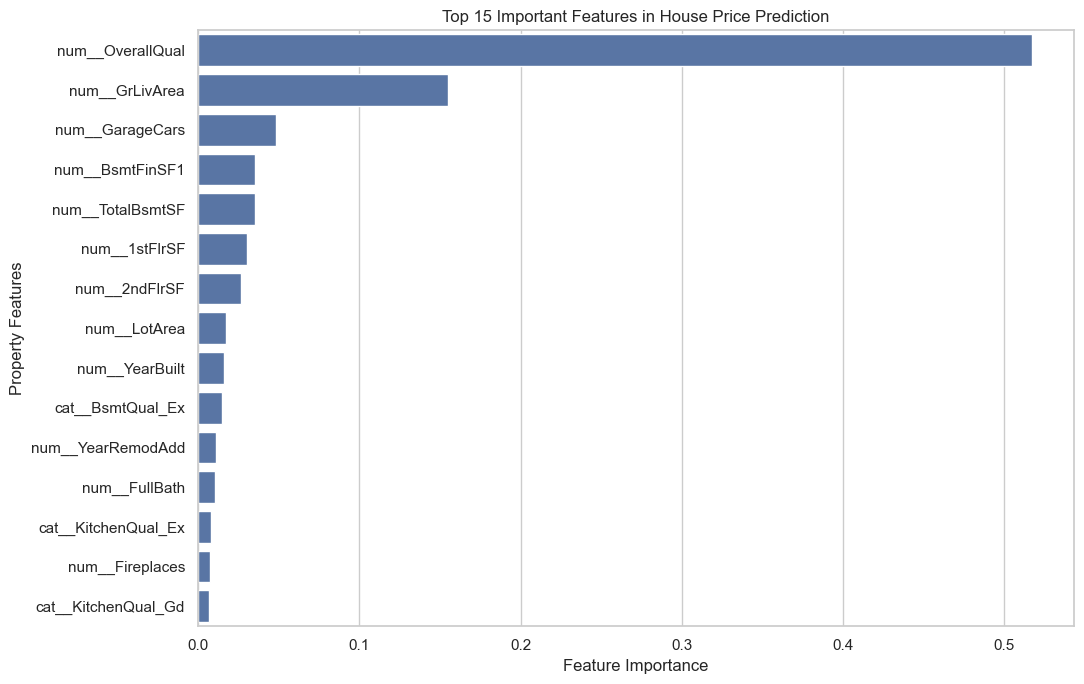

In [31]:
plt.figure(figsize=(11, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features in House Price Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Property Features")
plt.tight_layout()
plt.show()

# 14. Actual vs Predicted House Prices

This analysis compares the actual house prices with the prices predicted by the final selected machine learning model.

It helps us visually evaluate how accurately the model predicts house prices on unseen testing data.

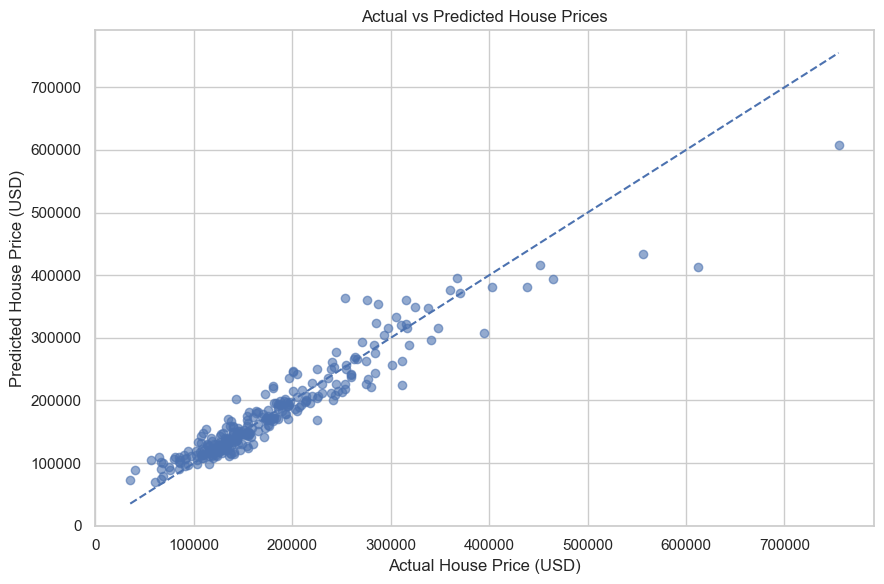

In [32]:
plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    final_predictions,
    alpha=0.6
)

min_price = min(y_test.min(), final_predictions.min())
max_price = max(y_test.max(), final_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual House Price (USD)")
plt.ylabel("Predicted House Price (USD)")
plt.tight_layout()
plt.show()

# 15. Residual Analysis

Residual analysis examines the differences between actual and predicted house prices.

It helps identify prediction errors and determine whether the model consistently overestimates or underestimates house prices.

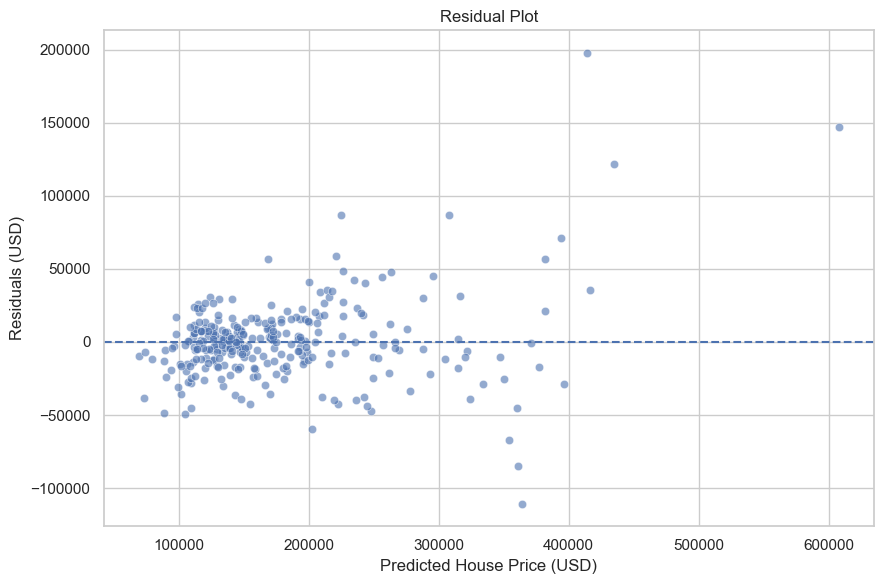

In [33]:
residuals = y_test - final_predictions

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=final_predictions,
    y=residuals,
    alpha=0.6
)

plt.axhline(y=0, linestyle="--")

plt.title("Residual Plot")
plt.xlabel("Predicted House Price (USD)")
plt.ylabel("Residuals (USD)")
plt.tight_layout()
plt.show()

# 16. House Price Prediction Demonstration

In this section, the final trained machine learning model is used to predict house prices for sample properties from the testing dataset.

The predicted prices are compared with their actual prices to demonstrate the practical application of the model.

In [34]:
# Select five sample houses from the testing dataset
sample_houses = X_test.head(5)

# Get their actual prices
actual_prices = y_test.loc[sample_houses.index]

# Predict their prices
predicted_prices = final_pipeline.predict(sample_houses)

# Create a comparison table
prediction_comparison = pd.DataFrame({
    "Actual Price (USD)": actual_prices.values,
    "Predicted Price (USD)": predicted_prices,
    "Absolute Error (USD)": np.abs(
        actual_prices.values - predicted_prices
    )
})

display(prediction_comparison.round(2))

,Actual Price (USD),Predicted Price (USD),Absolute Error (USD)
0,154500,142708.75,11791.25
1,325000,350050.72,25050.72
2,115000,126907.82,11907.82
3,159000,156209.93,2790.07
4,315500,321634.78,6134.78


# 17. Project Conclusion

This project developed a machine learning-based house price prediction system using the Ames Housing dataset.

The dataset was explored, cleaned, and preprocessed to handle missing values and categorical variables. Exploratory Data Analysis was performed to understand the relationship between property characteristics and house prices.

Four regression algorithms were trained and compared: Linear Regression, Decision Tree, Random Forest, and Gradient Boosting. Model performance was evaluated using MAE, MSE, RMSE, and R² score. Cross-validation was also performed to assess model consistency.

The best-performing model was selected based on cross-validation RMSE and evaluated on unseen testing data.

The project demonstrates how machine learning can help estimate residential property prices using features such as living area, overall quality, neighbourhood, and other property characteristics.

The developed model can serve as a foundation for more advanced real estate price estimation applications.

# 18. Project Limitations

1. The model is trained on historical housing data from Ames, Iowa, and may not accurately represent property prices in other locations.
2. The dataset contains information from a limited period and may not reflect current real estate market conditions.
3. Missing values and outliers may affect model performance.
4. The model's predictions depend on the quality and availability of input property features.
5. The model estimates prices based on historical patterns and cannot guarantee actual selling prices.
6. The dataset does not include all external factors, such as current economic conditions, interest rates, and future neighbourhood development.

# 19. Future Scope

1. The model can be trained using larger and more recent real estate datasets.
2. Advanced algorithms such as XGBoost, LightGBM, and CatBoost can be explored.
3. Hyperparameter tuning can be performed to improve model performance.
4. A user-friendly web or mobile application can be developed for house price estimation.
5. Additional factors such as transportation facilities, market trends, and nearby amenities can be incorporated.
6. The model can be extended to support property price estimation across multiple cities and regions.

# 20. References

1. Ames Housing Dataset – Kaggle.
2. Pandas Documentation – https://pandas.pydata.org/docs/
3. NumPy Documentation – https://numpy.org/doc/
4. Matplotlib Documentation – https://matplotlib.org/stable/
5. Seaborn Documentation – https://seaborn.pydata.org/
6. Scikit-learn Documentation – https://scikit-learn.org/stable/
7. Python Documentation – https://docs.python.org/3/